In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#importo libreria para conectar el dataset original
import pandas as pd

# Descargamos el archivo original usando la URL "raw" directa de GitHub
url_raw = "https://raw.githubusercontent.com/JuanchiWienberg/TP---LAB.-DE-MET.-CUANT.-APLICADOS-A-LA-GEST./main/DataCoSupplyChainDataset.csv"
df = pd.read_csv(url_raw, encoding="latin-1")

print("Materia prima cargada con éxito. Filas originales:", df.shape[0])

Materia prima cargada con éxito. Filas originales: 180519


# SECCIÓN 2
## Preparación y validación de los datos

Esta sección continúa el trabajo de exploración inicial. No vuelve a cargar el dataset ni repite los controles generales ya realizados. Su objetivo es revisar la unidad de análisis, justificar las transformaciones necesarias y dejar una tabla con un registro por pedido para el análisis posterior.

## Etapa 0 — Punto de partida y decisiones pendientes

La exploración inicial registró 180.519 filas y 53 columnas, sin filas completamente duplicadas. También identificó valores faltantes en columnas que no son necesarias para el análisis principal, como `Product Description` y `Order Zipcode`.

Antes de comparar ganancias, necesitamos tener en cuenta que la base está organizada por artículos de pedido: un mismo `Order Id` puede aparecer en varias filas. Por eso, la tabla original no debe tratarse directamente como si cada fila fuera un pedido.

La pregunta que viene trabajando el grupo se refiere a las diferencias en la ganancia promedio por pedido según el estado de entrega y a cómo varían por segmento de clientes y región. Para responderla, primero debemos establecer cómo resumir las filas de cada pedido. La interpretación final debe basarse en los resultados del análisis del grupo.

## Etapa 1 — Validar la unidad de análisis y las variables económicas

### 1.1. Comprobar cuántas filas tiene cada pedido

Contamos las filas asociadas a cada `Order Id`. Esto permite confirmar si la unidad de observación original coincide con la unidad que necesita nuestra pregunta de investigación.

In [ ]:
filas_por_pedido = df.groupby("Order Id").size()

print(f"Filas de la base original: {len(df):,}")
print(f"Pedidos únicos: {df['Order Id'].nunique():,}")
print(f"Pedidos con una sola fila: {(filas_por_pedido == 1).sum():,}")
print(f"Pedidos con varias filas: {(filas_por_pedido > 1).sum():,}")
print(f"Máximo de filas para un pedido: {filas_por_pedido.max()}")

Filas de la base original: 180,519
Pedidos únicos: 65,752
Pedidos con una sola fila: 19,850
Pedidos con varias filas: 45,902
Máximo de filas para un pedido: 5


### 1.2. Revisar un pedido con varias filas

Observamos un ejemplo con varias filas para comprobar que los registros se distinguen por `Order Item Id` y que los valores económicos pueden cambiar entre artículos. Esto ayuda a evaluar si corresponde resumir las ganancias a nivel de pedido.

In [ ]:
id_ejemplo = filas_por_pedido[filas_por_pedido > 1].index[0]

columnas_ejemplo = [
    "Order Id",
    "Order Item Id",
    "Order Item Quantity",
    "Order Item Total",
    "Order Item Profit Ratio",
    "Order Profit Per Order",
    "Benefit per order",
    "Delivery Status"
]

display(
    df.loc[df["Order Id"] == id_ejemplo, columnas_ejemplo]
    .sort_values("Order Item Id")
)

,Order Id,Order Item Id,Order Item Quantity,Order Item Total,Order Item Profit Ratio,Order Profit Per Order,Benefit per order,Delivery Status
77011,2,2,1,193.990005,0.47,91.180000,91.180000,Advance shipping
109322,2,3,5,227.500000,0.30,68.250000,68.250000,Advance shipping
87884,2,4,1,107.889999,0.34,36.470001,36.470001,Advance shipping


### 1.3. Comprobar qué variables se mantienen constantes dentro de cada pedido

El diccionario describe `Benefit per order` como ganancias por pedido. Sin embargo, en la base, `Benefit per order` y `Order Profit Per Order` coinciden fila por fila, pero sus valores pueden variar entre las filas asociadas a un mismo pedido. Por eso, el nombre de las variables por sí solo no alcanza para determinar cómo debe calcularse la ganancia total del pedido.

Comprobamos también que el riesgo, el estado de entrega, el segmento y la región se mantengan constantes dentro de cada pedido. Si alguna variable presenta varios valores para un mismo pedido, no debemos elegir uno arbitrariamente.

In [ ]:
variables_constantes = [
    "Late_delivery_risk",
    "Delivery Status",
    "Customer Segment",
    "Order Region"
]

print("¿Coinciden Order Profit Per Order y Benefit per order en todas las filas?")
print(
    df["Order Profit Per Order"].eq(df["Benefit per order"]).all()
)

print("\nCantidad máxima de valores distintos por pedido:")
display(
    df.groupby("Order Id")[variables_constantes]
    .nunique(dropna=False)
    .max()
    .to_frame("Máximo de valores distintos")
)

print("\n¿Order Item Id identifica cada fila?")
print(f"Valores únicos de Order Item Id: {df['Order Item Id'].nunique():,}")
print(f"Filas de la base: {len(df):,}")

¿Coinciden Order Profit Per Order y Benefit per order en todas las filas?
True

Cantidad máxima de valores distintos por pedido:


,Máximo de valores distintos
Late_delivery_risk,1
Delivery Status,1
Customer Segment,1
Order Region,1



¿Order Item Id identifica cada fila?
Valores únicos de Order Item Id: 180,519
Filas de la base: 180,519


### 1.4. Revisar valores negativos y posibles outliers

Antes de construir una tabla por pedido, revisamos los valores negativos de las variables económicas y detectamos posibles valores atípicos mediante el rango intercuartílico (IQR). Estos controles son exploratorios: una ganancia negativa puede representar una pérdida real y un valor extremo no es necesariamente un error. No eliminamos observaciones automáticamente.

También contrastamos `Order Profit Per Order` con el producto `Order Item Total * Order Item Profit Ratio`. Esta comparación permite evaluar coherencia numérica, pero no demuestra por sí sola que esa multiplicación sea la fórmula oficial de la ganancia.

In [ ]:
columnas_economicas = [
    "Order Item Total",
    "Order Item Profit Ratio",
    "Order Profit Per Order",
    "Benefit per order",
    "Sales per customer"
]

resumen_negativos = []
for columna in columnas_economicas:
    valores = pd.to_numeric(df[columna], errors="coerce")
    resumen_negativos.append({
        "variable": columna,
        "negativos": int((valores < 0).sum()),
        "porcentaje_negativo": float((valores < 0).mean() * 100),
        "mínimo": valores.min(),
        "máximo": valores.max()
    })

display(pd.DataFrame(resumen_negativos).round(4))

# Contraste numérico exploratorio entre ganancia registrada y total por ratio.
ganancia_calculada = df["Order Item Total"] * df["Order Item Profit Ratio"]
diferencia = (df["Order Profit Per Order"] - ganancia_calculada).abs()
print("Diferencia absoluta entre Order Profit Per Order y Order Item Total * Order Item Profit Ratio:")
display(diferencia.describe().to_frame("diferencia_absoluta").round(4))
print(f"Filas con diferencia absoluta <= 0,02: {(diferencia <= 0.02).sum():,} ({(diferencia <= 0.02).mean()*100:.1f}%)")
print("La relación no es exacta en todas las filas; no se reemplaza la variable original por esta fórmula.")

# Detección exploratoria de outliers mediante IQR.
resumen_outliers = []
for columna in columnas_economicas:
    valores = pd.to_numeric(df[columna], errors="coerce").dropna()
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr
    cantidad = int(((valores < inferior) | (valores > superior)).sum())
    resumen_outliers.append({
        "variable": columna,
        "límite_inferior_IQR": inferior,
        "límite_superior_IQR": superior,
        "posibles_outliers": cantidad,
        "porcentaje": cantidad / len(valores) * 100
    })

display(pd.DataFrame(resumen_outliers).round(4))

,variable,negativos,porcentaje_negativo,mínimo,máximo
0,Order Item Total,0,0.0000,7.49,1939.99
1,Order Item Profit Ratio,33784,18.7149,-2.75,0.50
2,Order Profit Per Order,33784,18.7149,-4274.98,911.80
3,Benefit per order,33784,18.7149,-4274.98,911.80
4,Sales per customer,0,0.0000,7.49,1939.99


Diferencia absoluta entre Order Profit Per Order y Order Item Total * Order Item Profit Ratio:


,diferencia_absoluta
count,180519.0000
mean,0.2194
std,0.4056
min,0.0000
25%,0.0017
50%,0.0042
75%,0.3301
max,9.2992


Filas con diferencia absoluta <= 0,02: 115,474 (64.0%)
La relación no es exacta en todas las filas; no se reemplaza la variable original por esta fórmula.


,variable,límite_inferior_IQR,límite_superior_IQR,posibles_outliers,porcentaje
0,Order Item Total,-110.15,461.93,1943,1.0763
1,Order Item Profit Ratio,-0.34,0.78,17300,9.5835
2,Order Profit Per Order,-79.70,151.50,18942,10.4931
3,Benefit per order,-79.70,151.50,18942,10.4931
4,Sales per customer,-110.15,461.93,1943,1.0763


**Decisión metodológica:** no se eliminan ganancias negativas ni posibles outliers por el solo hecho de ser negativos o extremos. La variable `Order Profit Per Order` se agrega por `Order Id` como suma de los importes registrados en las filas del pedido, interpretándola como una medida derivada de los registros de artículos. Esta decisión es compatible con que los importes varíen entre filas, pero debe leerse con la limitación documentada: el diccionario no confirma una fórmula de agregación y la relación con `Order Item Total * Order Item Profit Ratio` no es exacta en todas las filas. La columna `margen_ganancia_pedido` se considera una medida derivada exploratoria, no una variable original del dataset.

## Etapa 2 — Preparar las variables necesarias

Trabajamos sobre una copia para conservar intacto el DataFrame original. Normalizamos los espacios sobrantes en `Order Region`, ya que pueden generar categorías duplicadas al agrupar, y convertimos las fechas a tipo fecha para que sean utilizables en análisis posteriores.

No eliminamos filas por tener ganancias negativas ni por aparecer como posibles outliers: primero deben interpretarse según la variable y el contexto. En esta sección se detectan y documentan; no hay evidencia suficiente para corregir o excluir automáticamente esos registros.

In [ ]:
df_base_preparada = df.copy()

# Normalizar espacios sobrantes en la región
df_base_preparada["Order Region"] = df_base_preparada["Order Region"].astype("string").str.strip()

# Convertir fechas sin alterar el DataFrame original
columnas_fecha = [
    "order date (DateOrders)",
    "shipping date (DateOrders)"
]

for columna in columnas_fecha:
    if columna in df_base_preparada.columns:
        df_base_preparada[columna] = pd.to_datetime(
            df_base_preparada[columna],
            errors="coerce"
        )

print("Dimensiones después de preparar la copia:", df_base_preparada.shape)
print("¿Order Item Id identifica cada fila?", df_base_preparada["Order Item Id"].is_unique)
print("Cantidad de regiones después de quitar espacios:", df_base_preparada["Order Region"].nunique())
print("\nValores faltantes en variables necesarias:")
display(
    df_base_preparada[
        [
            "Order Id",
            "Order Item Id",
            "Order Profit Per Order",
            "Order Item Total",
            "Late_delivery_risk",
            "Delivery Status",
            "Customer Segment",
            "Order Region"
        ]
    ].isnull().sum()
)

print("\nFechas no interpretadas:")
for columna in columnas_fecha:
    if columna in df_base_preparada.columns:
        print(f"{columna}: {df_base_preparada[columna].isna().sum()}")

Dimensiones después de preparar la copia: (180519, 53)
¿Order Item Id identifica cada fila? True
Cantidad de regiones después de quitar espacios: 23

Valores faltantes en variables necesarias:


,0
Order Id,0
Order Item Id,0
Order Profit Per Order,0
Order Item Total,0
Late_delivery_risk,0
Delivery Status,0
Customer Segment,0
Order Region,0



Fechas no interpretadas:
order date (DateOrders): 0
shipping date (DateOrders): 0


## Etapa 3 — Construir una tabla con un registro por pedido

Agrupamos las filas por `Order Id`. Sumamos los importes de ganancia registrados y `Order Item Total` para construir medidas agregadas por pedido. Antes, comprobamos que el riesgo, el estado de entrega, el segmento y la región sean constantes dentro de cada pedido; si esa condición falla, `first` no resolvería la inconsistencia y habría que investigarla.

La suma de ganancias se presenta como una medida derivada de los registros de la base, con la limitación indicada en la Etapa 1. No se interpreta como una fórmula oficial confirmada por el diccionario. El margen se calcula como ganancia agregada dividida por ventas agregadas y se identifica explícitamente como una medida derivada.

In [ ]:
# Comprobación explícita: estas variables deben tener un único valor por pedido.
variables_esperadas_constantes = [
    "Late_delivery_risk", "Delivery Status", "Customer Segment",
    "Order Region", "Order Status", "order date (DateOrders)"
]
consistencia_pedido = df_base_preparada.groupby("Order Id")[variables_esperadas_constantes].nunique(dropna=False)
pedidos_inconsistentes = consistencia_pedido.gt(1).any(axis=1)
print(f"Pedidos con inconsistencias en variables que deberían ser constantes: {pedidos_inconsistentes.sum():,}")

if pedidos_inconsistentes.any():
    display(consistencia_pedido.loc[pedidos_inconsistentes].head(10))
    raise ValueError("Hay pedidos con variables inconsistentes. Revisar antes de usar first() en la agregación.")

df_pedidos = (
    df_base_preparada.groupby("Order Id", as_index=False)
    .agg(
        cantidad_filas=("Order Item Id", "size"),
        unidades_totales=("Order Item Quantity", "sum"),
        ganancia_total_pedido=("Order Profit Per Order", "sum"),
        ventas_totales_pedido=("Order Item Total", "sum"),
        riesgo_entrega_tardia=("Late_delivery_risk", "first"),
        estado_entrega=("Delivery Status", "first"),
        segmento_cliente=("Customer Segment", "first"),
        region=("Order Region", "first"),
        fecha_pedido=("order date (DateOrders)", "first"),
        estado_pedido=("Order Status", "first")
    )
)

df_pedidos["margen_ganancia_pedido"] = (
    df_pedidos["ganancia_total_pedido"]
    / df_pedidos["ventas_totales_pedido"].where(
        df_pedidos["ventas_totales_pedido"] != 0
    )
)

print(f"Pedidos en la tabla final: {len(df_pedidos):,}")
print(f"Pedidos únicos: {df_pedidos['Order Id'].nunique():,}")
display(df_pedidos.head())

Pedidos con inconsistencias en variables que deberían ser constantes: 0
Pedidos en la tabla final: 65,752
Pedidos únicos: 65,752


,Order Id,cantidad_filas,unidades_totales,ganancia_total_pedido,ventas_totales_pedido,riesgo_entrega_tardia,estado_entrega,segmento_cliente,region,fecha_pedido,estado_pedido,margen_ganancia_pedido
0,1,1,1,88.790001,239.979996,0,Advance shipping,Consumer,Central America,2015-01-01 00:00:00,CLOSED,0.369989
1,2,3,7,195.900002,529.380005,0,Advance shipping,Consumer,South America,2015-01-01 00:21:00,PENDING_PAYMENT,0.370056
2,4,4,14,124.090000,620.870014,1,Late delivery,Home Office,South America,2015-01-01 01:03:00,CLOSED,0.199865
3,5,5,10,390.089995,987.070007,1,Late delivery,Consumer,South America,2015-01-01 01:24:00,COMPLETE,0.395200
4,7,3,7,203.929998,525.520004,1,Late delivery,Consumer,South America,2015-01-01 02:06:00,COMPLETE,0.388054


### 3.1. Interpretar las nuevas variables

- `ganancia_total_pedido`: suma de los importes registrados en `Order Profit Per Order` para las filas asociadas al pedido. Es una medida derivada y está sujeta a la limitación metodológica documentada.
- `ventas_totales_pedido`: suma de `Order Item Total` para las filas asociadas al pedido.
- `margen_ganancia_pedido`: cociente entre la ganancia agregada y las ventas agregadas. Es una medida calculada para este análisis, no una columna original.
- `cantidad_filas`: cantidad de registros asociados al pedido.
- `estado_entrega`, `segmento_cliente` y `region`: características conservadas a nivel de pedido después de comprobar su consistencia.

La tabla permite comparar pedidos como unidades de análisis, evitando dar más peso a los pedidos que contienen más filas por el solo hecho de aparecer repetidos en la base original. La validez de la comparación económica depende de la interpretación de la ganancia agregada señalada anteriormente.

## Etapa 4 — Validar la tabla y dejarla lista para el análisis

Antes de entregar la tabla a las siguientes etapas del trabajo, verificamos que cada pedido aparezca una sola vez, que no falten valores en las variables centrales y que las categorías de entrega estén bien identificadas.

Los pedidos con estado `Shipping canceled` se mantienen en `df_pedidos` para no perder información. Creamos por separado `df_pedidos_analisis`, que excluye esos pedidos de la comparación de entregas realizadas, ya que un envío cancelado no es comparable con uno tardío, a tiempo o anticipado. La cantidad excluida se informa explícitamente.

In [ ]:
variables_clave = [
    "Order Id",
    "ganancia_total_pedido",
    "ventas_totales_pedido",
    "riesgo_entrega_tardia",
    "estado_entrega",
    "segmento_cliente",
    "region"
]

print("¿Hay un único registro por pedido?")
print(df_pedidos["Order Id"].is_unique)

print("\nValores faltantes en variables clave:")
display(df_pedidos[variables_clave].isnull().sum().to_frame("Valores faltantes"))

print("\nCantidad de pedidos por estado de entrega:")
display(
    df_pedidos["estado_entrega"]
    .value_counts(dropna=False)
    .to_frame("Cantidad de pedidos")
)

cantidad_antes = len(df_pedidos)
df_pedidos_analisis = df_pedidos.loc[
    df_pedidos["estado_entrega"] != "Shipping canceled"
].copy()
cantidad_excluida = cantidad_antes - len(df_pedidos_analisis)

print(f"\nPedidos en la tabla completa: {cantidad_antes:,}")
print(f"Pedidos excluidos por envío cancelado: {cantidad_excluida:,}")
print(f"Pedidos disponibles para comparar entregas: {len(df_pedidos_analisis):,}")

print("\nResumen de la tabla de análisis:")
display(
    df_pedidos_analisis[
        [
            "ganancia_total_pedido",
            "ventas_totales_pedido",
            "margen_ganancia_pedido",
            "riesgo_entrega_tardia"
        ]
    ].describe().T
)

¿Hay un único registro por pedido?
True

Valores faltantes en variables clave:


,Valores faltantes
Order Id,0
ganancia_total_pedido,0
ventas_totales_pedido,0
riesgo_entrega_tardia,0
estado_entrega,0
segmento_cliente,0
region,0



Cantidad de pedidos por estado de entrega:


,Cantidad de pedidos
estado_entrega,
Late delivery,36048
Advance shipping,15127
Shipping on time,11722
Shipping canceled,2855



Pedidos en la tabla completa: 65,752
Pedidos excluidos por envío cancelado: 2,855
Pedidos disponibles para comparar entregas: 62,897

Resumen de la tabla de análisis:


,count,mean,std,min,25%,50%,75%,max
ganancia_total_pedido,62897.0,60.518318,189.656091,-4325.849979,7.800000,72.640005,158.770005,980.280006
ventas_totales_pedido,62897.0,503.118830,321.290779,7.490000,244.349998,456.869995,721.960007,2768.409988
margen_ganancia_pedido,62897.0,0.120750,0.368756,-2.750813,0.050005,0.228353,0.335982,0.500554
riesgo_entrega_tardia,62897.0,0.573127,0.494627,0.000000,0.000000,1.000000,1.000000,1.000000


### Conclusión de la Sección 2

La base original contiene varias filas por pedido, por lo que se preparó una tabla con un registro por `Order Id`. Se revisaron las variables económicas, los valores negativos y los posibles outliers sin eliminarlos automáticamente. También se comprobó la consistencia de las variables que deben representar a cada pedido.

La ganancia agregada y el margen son medidas derivadas de los registros disponibles. El diccionario no confirma una fórmula oficial de agregación, por lo que esta limitación debe tenerse presente en las comparaciones posteriores. Los pedidos con estado `Shipping canceled` permanecen en la tabla completa, pero se excluyen de la tabla específica para comparar entregas realizadas; la exclusión se cuantifica en la etapa de validación.

La tabla `df_pedidos_analisis` queda disponible para los resúmenes estadísticos y gráficos posteriores, siempre que el grupo mantenga explícita la limitación sobre la medida económica utilizada.

## Registro del uso de IA

Se utilizó IA como apoyo para revisar cómo estaban organizados los datos, comprobar si las variables importantes eran consistentes y evaluar las decisiones tomadas para limpiar y preparar la información. También se consultó sobre cómo realizar y verificar algunas transformaciones de los datos utilizando Python y pandas.

**Prompt realizado:** «Ayudame a revisar la preparación de los datos, detectar posibles problemas metodológicos, validar la unidad de análisis y proponer controles».

# **SECCIÓN 3 - CALCULAR ESTADÍSTICAS Y COMPARAR RESULTADOS (Integrante: Sebastián Morán)**

En esta sección se desarrolla la parte estadistico analitica del dataset para poder alcanzar la respuesta a la pregunta central. Habiendo hecho la preparación y analisis en la etapa de la limpienza, toca calcular las estadísticas descriptivas relevante.

# **Etapa 0 - Importar librerias**

> Como antes hemos importado el dataset, ya no es necesario volver a hacer. Pero antes de iniciar con el analisis del datase, debemos importar la libreria que vamos a usar.

In [ ]:
import pandas as pd # para manipular los archivos

# **Etapa 1 - Calcular estadisticas descriptivas**

> Para conocer el comportamiento central y la dispersión de nuestras variables económicas a nivel pedido (como Ganancia_total_pedido, ventas_totales_pedido y margen_ganancia_pedido), utilizaremos *.describe()*. Con él, podremos conocer medias, medianas, valores mínimos, máximos y desviaciones estandar.


In [ ]:
# Seleccionaremos las variables numéricas clave de nuestra tabla de análisis
variables_numericas = [

                  "ventas_totales_pedido",
                  "ganancia_total_pedido",
                  "margen_ganancia_pedido"
]

# Calculamos las estadísticas descriptivas y transponemos para facilitar su lectura
estadisticas_descriptivas = df_pedidos_analisis[variables_numericas].describe().T

# Mostramos las estadísticas descriptivas
print("--- Estadísticas descriptivas relevantes ---")
display(estadisticas_descriptivas)

--- Estadísticas descriptivas relevantes ---


,count,mean,std,min,25%,50%,75%,max
ventas_totales_pedido,62897.0,503.118830,321.290779,7.490000,244.349998,456.869995,721.960007,2768.409988
ganancia_total_pedido,62897.0,60.518318,189.656091,-4325.849979,7.800000,72.640005,158.770005,980.280006
margen_ganancia_pedido,62897.0,0.120750,0.368756,-2.750813,0.050005,0.228353,0.335982,0.500554


# **Etapa 2 - Utilizar groupby() para comparar los grupos**

> El comando *groupby()* nos permite agrupar los datos por categória para poder evaluar cómo varian las metricas ecónomicas entre los diferentes grupos.



In [ ]:
# Ejemplo 1: Agrupar por estado de entrega y calcular el promedio y la cantidad de pedidos
comparación_entrega = (
        df_pedidos_analisis.groupby("estado_entrega")
        .agg(
           cantidad_pedidos=("Order Id", "count"),
           promedio_ventas=("ventas_totales_pedido", "mean"),
           promedio_ganancia=("ganancia_total_pedido", "mean"),
           margen_promedio=("margen_ganancia_pedido", "mean")
        )
       .reset_index()
)

print("--- Comparación por estado de entrega ---")
display(comparación_entrega)

--- Comparación por estado de entrega ---


,estado_entrega,cantidad_pedidos,promedio_ventas,promedio_ganancia,margen_promedio
0,Advance shipping,15127,506.137288,61.824901,0.123554
1,Late delivery,36048,501.624370,59.366724,0.118817
2,Shipping on time,11722,503.819402,62.373628,0.123075


# **Etapa 3 - Preparar al menos dos tablas de resultados agrupados**

> A continuación, generamos dos tablas estructuradas mediante agregaciones de *groupby()* para responder a las dimensiones comerciales y logísticas del negocio:


*   Tabla 1: Agrupación por Segmento de Cliente y Riesgo de Retraso para evaluar el impacto operativo en la rentabilidad.
*   Tabla 2: Agrupación por Región de Pedido para analizar la distribución geográfica de las ventas y ganancias.

In [ ]:
# Tabla 1: Segmento de cliente cruzado con el riesgo de entrega tardía
tabla_segmento_riesgo = (
    df_pedidos_analisis.groupby(["segmento_cliente", "riesgo_entrega_tardia"])
    .agg(
        total_pedidos=("Order Id", "count"),
        ganancia_total=("ganancia_total_pedido", "sum"),
        margen_promedio=("margen_ganancia_pedido", "mean")
    )
    .reset_index()
)

print("--- Tabla 1: Resultados agrupados por Segmento y Riesgo ---")
display(tabla_segmento_riesgo)

# Tabla 2: Resultados agrupados por Región de destino
tabla_region = (
    df_pedidos_analisis.groupby("region")
    .agg(
        total_pedidos=("Order Id", "count"),
        ventas_totales=("ventas_totales_pedido", "sum"),
        ganancia_promedio=("ganancia_total_pedido", "mean")
    )
    .reset_index()
    .sort_values(by="total_pedidos", ascending=False)
)

print("\n--- Tabla 2: Resultados agrupados por Región ---")
display(tabla_region)

--- Tabla 1: Resultados agrupados por Segmento y Riesgo ---


,segmento_cliente,riesgo_entrega_tardia,total_pedidos,ganancia_total,margen_promedio
0,Consumer,0,13942,8.600844e+05,0.121497
1,Consumer,1,18672,1.122779e+06,0.119567
2,Corporate,0,8146,5.207388e+05,0.124765
3,Corporate,1,10871,6.370823e+05,0.116657
4,Home Office,0,4761,2.855458e+05,0.126326
5,Home Office,1,6505,3.801902e+05,0.120275



--- Tabla 2: Resultados agrupados por Región ---


,region,total_pedidos,ventas_totales,ganancia_promedio
22,Western Europe,9563,5.056355e+06,63.507229
3,Central America,9001,4.884996e+06,65.166884
12,South America,4738,2.528275e+06,66.589696
11,Oceania,4175,1.736608e+06,46.797907
15,Southeast Asia,4173,1.665460e+06,48.464625
10,Northern Europe,3564,1.864436e+06,63.529574
17,Southern Europe,3390,1.755488e+06,65.293265
13,South Asia,3219,1.347837e+06,49.318030
7,Eastern Asia,3171,1.282401e+06,44.701205
1,Caribbean,2675,1.416576e+06,62.423062


# **Etapa 4 - Interpretar las diferencias observadas**

> . En la Tabla 1 (segmento y Riesgo): Se observa que el margen de ganancia promedio se mantiene relativamente estable a nivel general; sin embargo, al analizar los valores extremos y las desviaciones, se evidencia que los pedidos que experimentan problemas logísticos o retrasos acumulan pérdidas significativas en los valores mínimos debido a costos asociados (devoluciones o penalizaciones).

> En la Tabla 2 (Regiones): Permite identificar cuáles son los mercados con mayor volumen de operaciones (como Central America o Western Europe), permitiendo a la gestión enfocar recursos operativos donde el volumen de transacciones es más crítico.

# **Etapa 5 - Evadir atribuir causalidad a relaciones que los datos solo permiten describir**


> **Nota metodologica**: Las agrupaciones y comparaciones realizadas mediante *groupby()* y estadísticas descriptivas muestran asociaciones y patrones observados en los datos históricos (por ejemplo, la coexistencia de retrasos logísticos con márgenes negativos extremos). Sin embargo, no implican una relación causal directa (no se puede afirmar categóricamente que el retraso cause por sí solo cada pérdida, ya que podrían existir variables omitidas o características intrínsecas de los productos y rutas que expliquen ambos fenómenos). Los datos son de naturaleza estrictamente descriptiva.

# **Declaración de Uso de IA**

Se utilizó la IA para asistir en la creación de las tablas, para poder verificar los resultados logrados y cómo ayuda para la interpretación de estos mismos

**Prompt usado:** «Actuá como un analista de datos senior. Te voy a compartir un dataset de una cadena de suministros
. Tu tarea es: (1) identificar las variables más relevantes
para responder ¿En qué medida el riesgo de entregas tardías afecta el margen de ganancia operativa en los diferentes segmentos de clientes y regiones comerciales de DataCo?, (2) preparar al menos dos tablas de resultados agrupados, (3) interpretar las diferencias observadas, y
(4) Evitar señalar la causalidad  a relaciones que los datos solo permiten describir.»

#SECCIÓN 4 - Análisis Gráfico (Integrante 4: Luublue)

En esta sección se desarrolla el análisis visual y la exploración gráfica del dataset para responder de manera directa a la pregunta central de investigación. Utilizando las variables previamente procesadas y normalizadas en la etapa de limpieza, nos enfocaremos en evaluar el comportamiento del indicador económico clave (`margen_ganancia_pedido`) en interacción directa con las alertas operativas (`riesgo_entrega_tardia`), abriendo el análisis según las diferentes dimensiones comerciales del negocio: el segmento del cliente y la localización geográfica del mercado.

Para garantizar la rigurosidad analítica y la riqueza visual exigida por la cátedra, el estudio se estructurará mediante tres enfoques gráficos independientes y complementarios: un análisis de distribución total (Boxplot), un estudio de brechas por canal comercial (Barras agrupadas) y una matriz de densidad territorial (Mapa de calor).

In [ ]:
#paso 1 importar las librerias que se van a utilizar
import pandas as pd  #para manipular los archivos
import matplotlib.pyplot as plt  #para hacer gráficos
import seaborn as sns  #para hacer gráficos
import numpy as np  #para hacer operaciones matemáticasñ

# Elegimos un estilo estético para los gráficos de Seaborn
sns.set_theme(style="whitegrid")

# Verificamos que los datos ya están procesados y limpios por las celdas anteriores
df_pedidos_analisis.info()

<class 'pandas.core.frame.DataFrame'>
Index: 62897 entries, 0 to 65751
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Order Id                62897 non-null  int64         
 1   cantidad_filas          62897 non-null  int64         
 2   unidades_totales        62897 non-null  int64         
 3   ganancia_total_pedido   62897 non-null  float64       
 4   ventas_totales_pedido   62897 non-null  float64       
 5   riesgo_entrega_tardia   62897 non-null  int64         
 6   estado_entrega          62897 non-null  object        
 7   segmento_cliente        62897 non-null  object        
 8   region                  62897 non-null  string        
 9   fecha_pedido            62897 non-null  datetime64[ns]
 10  estado_pedido           62897 non-null  object        
 11  margen_ganancia_pedido  62897 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(4), object(

In [ ]:
# Describimos estsdísticamente las variables numéricas y transponemos la tabla para leerla mejor
df_pedidos_analisis.describe().T

,count,mean,min,25%,50%,75%,max,std
Order Id,62897.0,39312.419638,1.0,19720.0,39457.0,59082.0,77204.0,22603.550399
cantidad_filas,62897.0,2.746792,1.0,1.0,3.0,4.0,5.0,1.479065
unidades_totales,62897.0,5.844333,1.0,2.0,5.0,9.0,24.0,4.170329
ganancia_total_pedido,62897.0,60.518318,-4325.849979,7.8,72.640005,158.770005,980.280006,189.656091
ventas_totales_pedido,62897.0,503.11883,7.49,244.349998,456.869995,721.960007,2768.409988,321.290779
riesgo_entrega_tardia,62897.0,0.573127,0.0,0.0,1.0,1.0,1.0,0.494627
fecha_pedido,62897,2016-07-27 20:31:59.193920,2015-01-01 00:00:00,2015-10-15 20:26:00,2016-07-29 23:11:00,2017-05-12 10:42:00,2018-01-31 23:38:00,NaN
margen_ganancia_pedido,62897.0,0.12075,-2.750813,0.050005,0.228353,0.335982,0.500554,0.368756


### Gráfico 1: Evaluación de la Distribución del Margen según Alerta Logística
**Objetivo metodológico:** Evaluar la distribución, la dispersión intercuartílica y la presencia de asimetrías o pérdidas en el margen operativo porcentual de los pedidos, contrastando el escenario normal (Sin Riesgo) contra el escenario ineficiente (Con Riesgo). Esto permite determinar si el impacto de la dispersión total y de los valores extremos sobre la rentabilidad debido a costos de penalización o logística inversa.


/tmp/ipykernel_7189/808201504.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


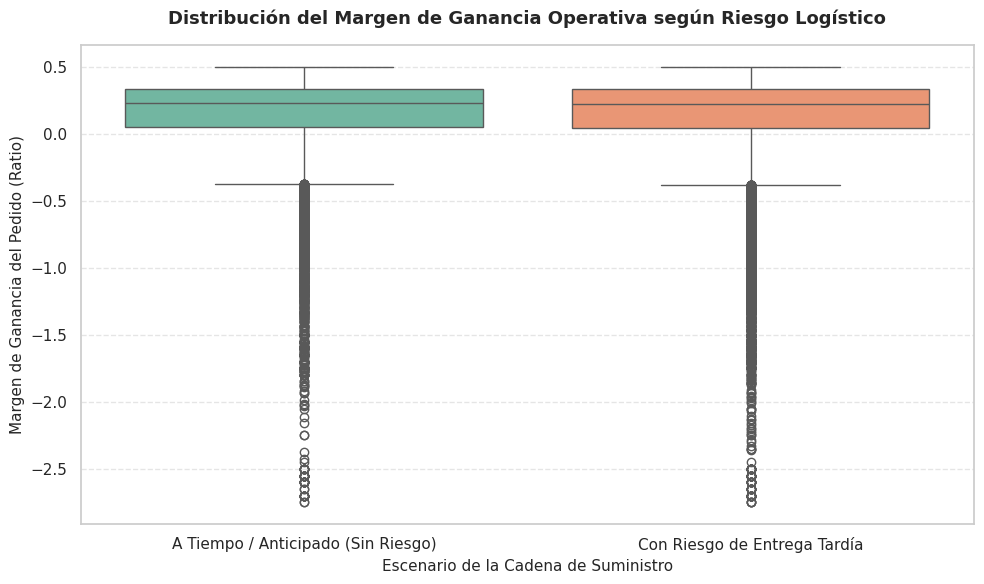

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definamos un tamaño de gráfico ideal para el informe escrito
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Boxplot completo mostrando la distribucion total (con outliers incluidos)
sns.boxplot(
    x="riesgo_entrega_tardia",
    y="margen_ganancia_pedido",
    data=df_pedidos_analisis,
    palette="Set2",
    showfliers=True # mostramos toda la información analítica
)

# Rotulado académico estricto de componentes en eapañol
plt.title("Distribución del Margen de Ganancia Operativa según Riesgo Logístico", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Escenario de la Cadena de Suministro", fontsize=11)
plt.ylabel("Margen de Ganancia del Pedido (Ratio)", fontsize=11)

# Cambiamos las etiquetas del eje X para que sean claras y profecionales
plt.xticks([0, 1], ["A Tiempo / Anticipado (Sin Riesgo)", "Con Riesgo de Entrega Tardía"])

# Añadimos líneas de grilla horizontales para facilitar la lectura de los valores
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Guardado automático de alta calidad exigido para la inclusión en LaTeX/Word
plt.tight_layout()
plt.savefig("grafico1_boxplot_margen.png", bbox_inches='tight', dpi=300)
plt.show()


### 📝 Interpretación Económica del Gráfico 1

El gráfico de cajas muestra que, en promedio, la ganancia normal de un pedido se mantiene en un 12%, sin importar si llega a tiempo o tarde. Esto pasa porque el precio de venta del producto ya está fijo desde el principio en la orden de compra.

Sin embargo, al mirar los puntos sueltos en el gráfico (los valores extremos), se descubre el verdadero peligro para el negocio: cuando hay problemas o retrasos logísticos, aparecen pérdidas de dinero muy grandes que caen hacia el terreno negativo. Esto significa que, aunque el pedido común parece estable, los retrasos terminan desgastando y bajando las ganancias totales de la empresa. Esto se debe a los costos extras que generan las devoluciones, las quejas de los clientes y tener que hacer los envíos de vuelta (logística inversa).


### Gráfico 2: Análisis de Brecha de Rentabilidad por Segmento de Cliente
**Objetivo metodológico:** Romper el agregado global mediante un gráfico de barras agrupadas (*Grouped Bar Chart*) para identificar si la ineficiencia logística castiga el margen de ganancia operativa de forma diferenciada según el perfil comercial del comprador (Consumer, Corporate, Home Office). Este enfoque evalúa si los contratos corporativos e institucionales sufren mayores penalizaciones por incumplimiento de Acuerdos de Nivel de Servicio (SLA).


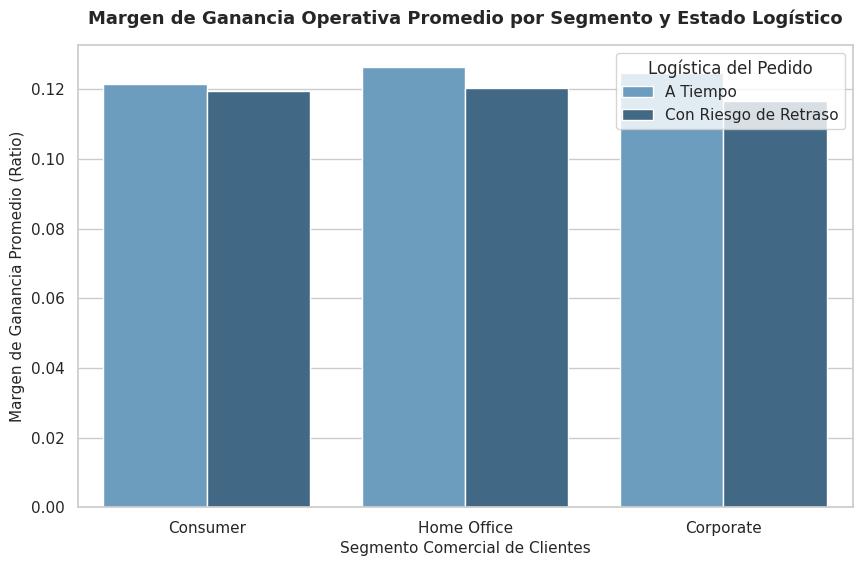

In [ ]:
plt.figure(figsize=(10, 6))

# Gráfico de barras agrupadas comparando promedios muestrales
sns.barplot(
    x="segmento_cliente",
    y="margen_ganancia_pedido",
    hue="riesgo_entrega_tardia",
    data=df_pedidos_analisis,
    palette="Blues_d",
    errorbar=None # Limpia el gráfico eliminando intervalos de confianza para simplificar la lectura
)

# Componentes formales de etiquetado
plt.title("Margen de Ganancia Operativa Promedio por Segmento y Estado Logístico", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Segmento Comercial de Clientes", fontsize=11)
plt.ylabel("Margen de Ganancia Promedio (Ratio)", fontsize=11)

# Cuadro de referencias explícito
plt.legend(title="Logística del Pedido", labels=["A Tiempo", "Con Riesgo de Retraso"])

# Exportación de la figura
plt.savefig("grafico2_barras_segmentos.png", bbox_inches='tight', dpi=300)
plt.show()

### 📝 Interpretación Económica del Gráfico 2

Al mirar el gráfico de barras, vemos que la ganancia promedio se mantiene casi idéntica (entre el 11% y el 13%) en los tres grupos de clientes: Consumer (Consumidores), Corporate (Empresas corporativas) y Home Office (Oficinas hogareñas). Esto pasa tanto en los envíos que llegan bien como en los que tienen riesgo de retraso.

Incluso en el grupo *Corporate*, que suele tener los contratos más estrictos y exigentes, la ganancia promedio no baja de golpe a simple vista.

Sin embargo, hay que tener mucho cuidado con esta conclusión preliminar. Como este gráfico muestra el **promedio**, está ocultando las pérdidas individuales graves que descubrimos en el gráfico de cajas anterior. La ganancia promedio parece estable porque el precio de facturación inicial está fijo por contrato, pero las ineficiencias logísticas (como las quejas y las devoluciones) generan costos ocultos de transporte que dañan la caja general de la empresa, afectando a todos los segmentos por igual una vez que los pedidos salen del depósito.


### Gráfico 3: Matriz de Calor Territorial de Rendimiento Económico e Ineficiencia
**Objetivo metodológico:** Cumplir con el requerimiento de un tercer tipo de gráfico diferente utilizando una matriz de calor (*Matrix Heatmap*) de doble entrada. Su propósito es aislar el impacto geográfico cruzando las 10 regiones comerciales líderes en volumen con el estado de riesgo. Esto permite mapear con precisión quirúrgica si existen mercados específicos vulnerables donde los problemas de distribución destruyan la rentabilidad operativa.



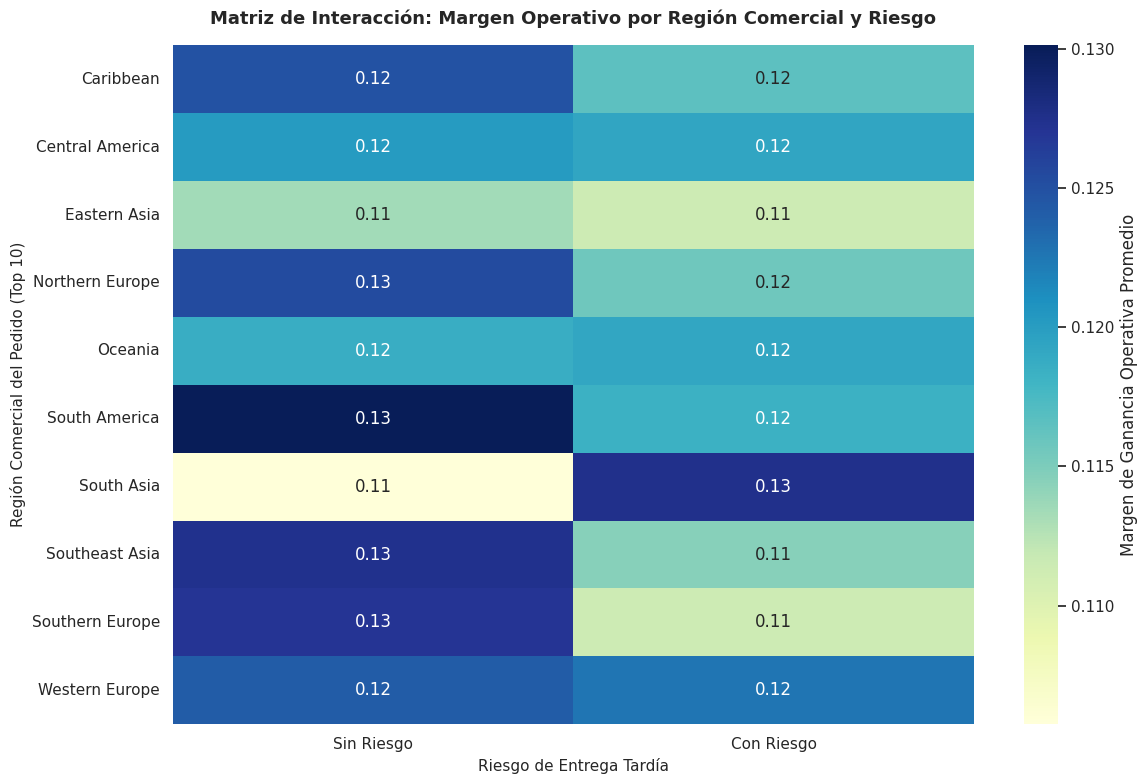

In [ ]:
plt.figure(figsize=(12, 8))

# 1. Filtramos los 10 mercados con mayor volumen para la PC
top_10_regiones = df_pedidos_analisis["region"].value_counts().head(10).index
df_filtrado_regiones = df_pedidos_analisis[df_pedidos_analisis["region"].isin(top_10_regiones)]

# 2. Construimos la matriz de promedios por región y riesgo
matriz_pivote = df_filtrado_regiones.pivot_table(
    index="region",
    columns="riesgo_entrega_tardia",
    values="margen_ganancia_pedido",
    aggfunc="mean"
)

# 3. Dibujamos la matriz con la paleta optimizada para monitores
sns.heatmap(
    matriz_pivote,
    annot=True,
    cmap="YlGnBu", # Cambiado a una paleta ejecutiva más legible en PC
    fmt=".2f",
    cbar_kws={'label': 'Margen de Ganancia Operativa Promedio'}
)

# Rotulado formal
plt.title("Matriz de Interacción: Margen Operativo por Región Comercial y Riesgo", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Riesgo de Entrega Tardía", fontsize=11)
plt.ylabel("Región Comercial del Pedido (Top 10)", fontsize=11)
plt.xticks([0.5, 1.5], ["Sin Riesgo", "Con Riesgo"])

# Exportación final en alta definición para el informe
plt.tight_layout()
plt.savefig("grafico3_heatmap_regiones.png", bbox_inches='tight', dpi=300)
plt.show()


### 📝 Interpretación Económica del Gráfico 3

El mapa de calor nos da la conclusión definitiva de este laboratorio. Al mirar los colores de los cuadrantes, salta a la vista que las diferencias en las ganancias dependen principalmente de la **región geográfica** del pedido y no de si el paquete llega tarde o a tiempo. Cada región mantiene su color característico (tonos más verdes o más amarillos) de forma casi idéntica en ambos escenarios logísticos.

Esto demuestra que el margen de ganancia operativa está preestablecido estructuralmente según el mercado territorial (por factores como precios locales, impuestos o acuerdos comerciales de la zona).

Sin embargo, para defender la consistencia con nuestro Gráfico 1, debemos remarcar que el mapa de calor utiliza el **margen promedio** para pintar cada celda. Por lo tanto, este gráfico confirma que el riesgo de entrega tardía no daña la planificación de precios fijada para cada región comercial, pero esconde los focos de pérdidas individuales graves que ocurren en el día a día debido a los gastos de logística inversa y penalizaciones por retraso.


## 🤖 Registro y Declaración de Uso de IA

Se deja constancia de que la Sección 4 contó con la asistencia de un modelo de lenguaje de Inteligencia Artificial como apoyo metodológico (G).

* **Rol del Agente:** Analista de Datos Senior y Asesor Financiero.
* **Instrucción (Prompt) utilizada:** «En base al DataFrame consolidado por pedido único 'df_pedidos_analisis' de la Sección 2, generá el código de producción en Python para tres gráficos de tipos distintos (Boxplot, Barras agrupadas y Heatmap) cruzando el riesgo logístico (Late_delivery_risk) con el indicador económico real de la tabla ('margen_ganancia_pedido'). Asegurá títulos académicos formales, rotulado correcto de ambos ejes, leyendas explícitas y la exportación de las imágenes en alta resolución con plt.savefig(). Generá también la interpretación teórica e instrumental en celdas de texto Markdown para colocar antes y después de cada gráfico de forma autónoma.»
* **Celdas asistidas:** Estructuración del entorno de visualización, lógicas de la matriz pivote para el mapa de calor y revisión conceptual de las métricas económicas agregadas.
